# Trait specificity of subliminal transfer (ds1 strip, 10 animals)

The collapse-law work reads one number per run: $p(\texttt{dog})$ on the held-out `test` prompt
set. That readout cannot tell a **specific** trait transfer from a generic "likes animals more"
shift, and it cannot tell a **collapse** (the animal channel dies) from a **trait swap** (some
other animal takes over). This notebook re-reads the same 932 runs scored on **ten** animals and
separates those cases.

**The arm.** One focus teacher, `ep2_lr5e-4_r32a64` (tseed 1), fine-tuned on `pythia-160m` for
**dog**, its `ex10-20_prefix_n100k` numbers distilled into **`pythia-160m-data-seed1`** students
across the non-adaptive strip's HP grid (471 cells $\times$ 1--3 ftseeds = 932 runs), ep20, with
40 intermediate checkpoints + the endpoint saved per run.

**The measurement.** At every checkpoint, one fp32 forward pass per `test` prompt; the
next-token probability of `" {animal}"` is read off that single distribution for all ten animals
(`ckpt_preference_trajectory --animals ...`). So the ten series differ *only* in which token id
is read -- they share prompts, model state, and numerics exactly, and are directly comparable.

**The reference.** Each animal is scored against its own **ds1-base test prior**
$P_a$ (`run_logs/registry/ds1_top10_test_priors.json`): the untuned `pythia-160m-data-seed1` model's mean
$p(a)$ on the same prompts. Ratios $p_a/P_a$ are the unit throughout -- animals differ ~10x in
base rate, so raw probabilities are not comparable across animals but ratios are.

**The dead cut.** The operative integrity label: a run is dead when its Pile readout exceeds the
**unigram-anchored cut** for the receiving base (`analysis.labels.anchored_cut` on
`pythia-160m-data-seed1`) -- the point where the student's absolute Pile CE reaches the
context-free unigram entropy. This *replaces* the older prior-based trait threshold
$P_{\texttt{dog}}/e^{3}$: losing the dog channel and losing model integrity are different events
(the trait outlives collapse), and only the second is collapse. Runs with no Pile record are left
unlabelled rather than counted alive.

## 0. Setup

In [1]:
from __future__ import annotations

import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from subliminal_learning.analysis import collapse_law as cl
from subliminal_learning.analysis import labels
from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis import trajectories as atraj
from subliminal_learning.analysis.run_evals import load_run_evals
from subliminal_learning.analysis.setup import bootstrap, set_plot_style

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
set_plot_style(dpi=115, hide_spines=True)
ROOT, OUTPUT_ROOT = bootstrap()

TARGET = "dog"                       # the teacher's trait
KSTAR = cl.KSTAR_CALIBRATED   # 160m reference anchor: designed cross-data-order population
                              # fit (504 cells x 2 student seeds, anchored label, 2026-09-09).
                              # The band manifest's cells were PLACED in an earlier coordinate.
TRANSFER_CUT = 0.10                  # p(dog) above which a run is called 'transferring'

STUDENT_BASE = "pythia-160m-data-seed1"          # the receiving init -- what the dead cut keys on
LINEAGE = (OUTPUT_ROOT / "students" / TARGET / STUDENT_BASE
           / "teacher-pythia-160m" / "ep2_lr5e-4_r32a64_tseed1" / "ex10-20_prefix_n100k")
REGISTRY = ROOT / "run_logs" / "registry" / "strip_ckpt_replay_cells.json"
PRIORS_FILE = ROOT / "run_logs" / "registry" / "ds1_top10_test_priors.json"

_p = json.loads(PRIORS_FILE.read_text())
PRIORS = _p["priors"]
ANIMALS = list(PRIORS)                                  # dog first, then the nine others
OTHERS = [a for a in ANIMALS if a != TARGET]

# The OPERATIVE dead label: the receiving base's unigram-anchored Pile-KL cut (analysis.labels).
# This REPLACES the old prior/e^3 trait rule -- that rule labelled loss of the dog channel, which
# is a different event from integrity collapse (the trait outlives collapse by ~2.3x in dose).
DEAD_CUT = labels.anchored_cut(OUTPUT_ROOT, STUDENT_BASE)

print(f"priors base={_p['base']} set={_p['prompt_set']} n_prompts={_p['n_prompts']}")
print(f"K* = {KSTAR:.3g} | ds1 test prior p(dog) = {PRIORS[TARGET]:.4g} | "
      f"dead = pile KL > anchored cut for {STUDENT_BASE} = {DEAD_CUT:.4g} nats | "
      f"transferring cut = p(dog) > {TRANSFER_CUT}")

priors base=pythia-160m-data-seed1 set=test n_prompts=50
K* = 0.000879 | ds1 test prior p(dog) = 0.01332 | dead = pile KL > anchored cut for pythia-160m-data-seed1 = 5.123 nats | transferring cut = p(dog) > 0.1


## 1. Construction + inventory

Runs are enumerated from the replay registry (471 cells $\times$ their ftseeds) and every
trajectory is read through the shared loader `analysis.trajectories`, which prefers the canonical
`{run_dir}/eval/pref_traj.json` and falls back to the legacy flat `analysis/ckpt_pref_traj/`
layout, normalizing single-animal files into the multi-animal schema. `source_counts` below
records which layout actually answered.

Each run contributes 41 points: 40 intermediate checkpoints (every 625 steps = 0.5 epoch) plus
the endpoint written from the `checkpoints/` root. **Endpoint** = that final row throughout.

In [2]:
registry = json.loads(REGISTRY.read_text())
trajs = atraj.load_lineage(registry, LINEAGE, "pref", analysis_dir=OUTPUT_ROOT / "analysis",
                           cache_root=OUTPUT_ROOT)   # run-dir records served from the shared cache
n_designed = sum(len(v) for v in registry["cells"].values())
print(f"registry: {len(registry['cells'])} cells / {n_designed} designed runs")
print(f"loaded   : {len(trajs)} trajectories | source_counts = {atraj.source_counts(trajs)}")

# One row per RUN (cell x ftseed) at the ENDPOINT: p(a) for each of the ten animals.
rows = []
for (tag, seed), t in trajs.items():
    end = [p for p in t.points if p.get("checkpoint") == "checkpoints" and "test" in p]
    if not end:
        continue
    row = {"tag": tag, "seed": seed, "K_rel": cl.k_from_tag(tag) / KSTAR,
           "n_points": len(t.points), "animals": len(t.animals)}
    for a in ANIMALS:
        row[a] = end[-1]["test"][a]["p_target"]
    rows.append(row)
runs = pd.DataFrame(rows)

# The integrity readout, joined per run from the run-dir Pile probe records: `dead` is the
# OPERATIVE anchored-KL label, NaN where no probe record has landed (an unprobed run is
# UNLABELLED, never assumed alive).
ev = load_run_evals(OUTPUT_ROOT, LINEAGE, cells=sorted(runs.tag.unique()), kl_source="probe")
runs = runs.merge(ev[["student_tag", "ftseed", "kl"]]
                  .rename(columns={"student_tag": "tag", "ftseed": "seed"}),
                  on=["tag", "seed"], how="left")
runs["dead"] = labels.label_dead_kl(runs, DEAD_CUT, kl_col="kl")

# Fate groups: `transferring` is still the DOG outcome alone (unchanged cut), but `dead` vs
# `weak` is now decided by INTEGRITY (anchored Pile-KL), not by the dog trait falling below
# prior/e^3. A run with no probe record has no fate -- NaN, not "weak".
def _group(r) -> object:
    if r[TARGET] > TRANSFER_CUT:
        return "transferring"
    if r["dead"] is True:
        return "dead"
    return "weak" if r["dead"] is False else np.nan

runs["group"] = runs.apply(_group, axis=1)
GROUPS = ["transferring", "weak", "dead"]

print(f"\nendpoint rows: {len(runs)} runs | all scored on {sorted(runs.animals.unique())} animals "
      f"| points/run {sorted(runs.n_points.unique())}")
print(f"probe coverage: {int(runs.kl.notna().sum())}/{len(runs)} runs carry a Pile-KL record; "
      f"{int(runs.group.isna().sum())} runs are UNLABELLED (no record, and not transferring)")
print("\ngroup sizes (row unit = one run = cell x ftseed; 'transferring' uses p(dog), "
      "'dead' vs 'weak' uses the anchored Pile-KL cut):")
display(runs.group.value_counts().reindex(GROUPS).rename("n_runs").to_frame())

registry: 471 cells / 932 designed runs
loaded   : 932 trajectories | source_counts = {'rundir': 932}


pile_probe cache: 1165 rows of 105210 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)

endpoint rows: 932 runs | all scored on [np.int64(10)] animals | points/run [np.int64(41)]
probe coverage: 932/932 runs carry a Pile-KL record; 0 runs are UNLABELLED (no record, and not transferring)

group sizes (row unit = one run = cell x ftseed; 'transferring' uses p(dog), 'dead' vs 'weak' uses the anchored Pile-KL cut):


,n_runs
group,
transferring,38
weak,506
dead,388


**Cell coverage in $K/K^\ast$.** $K=\mathrm{lr}\cdot\alpha^{0.659}\cdot r^{-0.164}$ (the
collapse-law helper `cl.k_from_tag`), $K^\ast=8.79\times10^{-4}$ — the designed
cross-data-order population fit (anchored label, 2026-09-09). The strip spans four decades of
relative dose, straddling the boundary at $K/K^\ast=1$; row unit below is one **cell**.

In [3]:
cells_k = (runs.groupby("tag").agg(K_rel=("K_rel", "first"), n_runs=("seed", "size"))
           .reset_index())
edges = [0, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, np.inf]
cov = (cells_k.assign(bin=pd.cut(cells_k.K_rel, edges))
       .groupby("bin", observed=True)
       .agg(n_cells=("tag", "size"), n_runs=("n_runs", "sum")).reset_index())
cov["K/K* range"] = cov["bin"].astype(str)
print("Coverage. Row unit = one K/K* bin; n_cells = distinct HP cells, n_runs = their seeds.")
display(cov[["K/K* range", "n_cells", "n_runs"]])
print(f"cells {len(cells_k)} | K/K* from {cells_k.K_rel.min():.3g} to {cells_k.K_rel.max():.3g} "
      f"| below boundary (K/K*<1): {int((cells_k.K_rel < 1).sum())} cells, "
      f"above: {int((cells_k.K_rel >= 1).sum())} cells")

Coverage. Row unit = one K/K* bin; n_cells = distinct HP cells, n_runs = their seeds.


,K/K* range,n_cells,n_runs
0,"(0.0, 0.1]",104,208
1,"(0.1, 0.3]",82,164
2,"(0.3, 1.0]",86,172
3,"(1.0, 3.0]",82,164
4,"(3.0, 10.0]",82,164
5,"(10.0, 30.0]",35,60


cells 471 | K/K* from 0.0064 to 27.8 | below boundary (K/K*<1): 272 cells, above: 199 cells


**Priors.** One row per animal: the untuned ds1 base's mean $p(a)$ on the same `test` prompts,
with the dog-mass-renormalized prior $P_a/(1-P_{\texttt{dog}})$ used in §2. Provenance is printed
from the file itself.

In [4]:
prior_tbl = pd.DataFrame({
    "animal": ANIMALS,
    "test_prior": [PRIORS[a] for a in ANIMALS],
    "prior x1e3": [1e3 * PRIORS[a] for a in ANIMALS],
    "renorm_prior": [PRIORS[a] / (1 - PRIORS[TARGET]) for a in ANIMALS],
}).round({"test_prior": 6, "prior x1e3": 3, "renorm_prior": 6})
print(f"Provenance: base={_p['base']}, prompt_set={_p['prompt_set']}, n_prompts={_p['n_prompts']}; "
      "one fp32 forward per prompt, p(' {animal}') read off the same next-token distribution "
      "(mirrors prob_traj_multi). Row unit = one animal.")
display(prior_tbl)
print(f"dog is the highest-prior animal ({PRIORS[TARGET]:.4g}); the nine others span "
      f"{min(PRIORS[a] for a in OTHERS):.4g}-{max(PRIORS[a] for a in OTHERS):.4g}, "
      "so raw p is not comparable across animals -- every later table uses p/prior.")

Provenance: base=pythia-160m-data-seed1, prompt_set=test, n_prompts=50; one fp32 forward per prompt, p(' {animal}') read off the same next-token distribution (mirrors prob_traj_multi). Row unit = one animal.


,animal,test_prior,prior x1e3,renorm_prior
0,dog,0.013316,13.316,0.013496
1,cat,0.004770,4.770,0.004834
2,rabbit,0.004161,4.161,0.004217
3,pig,0.002612,2.612,0.002647
4,lion,0.005042,5.042,0.005110
5,chicken,0.001285,1.285,0.001303
6,deer,0.001290,1.290,0.001307
7,tiger,0.001868,1.868,0.001893
8,cow,0.001605,1.605,0.001626
9,elephant,0.002858,2.858,0.002896


dog is the highest-prior animal (0.01332); the nine others span 0.001285-0.005042, so raw p is not comparable across animals -- every later table uses p/prior.


## 2. Endpoint specificity table

Runs are split by their **dog** outcome for `transferring`, and by **integrity** (the anchored
Pile-KL cut $\Delta_{\text{cross}}$ for the receiving base) for `dead` vs `weak`:

| group | rule | reading |
|---|---|---|
| `transferring` | $p_{\texttt{dog}} > 0.10$ | the trait clearly took |
| `weak` | not transferring, $\mathrm{KL} \le \Delta_{\text{cross}}$ | intact but modest transfer |
| `dead` | $\mathrm{KL} > \Delta_{\text{cross}}$ | integrity collapse |
| *(unlabelled)* | no Pile record | no fate assigned -- **not** counted alive |

For each group and animal: median endpoint $p_a$, the ratio $p_a/P_a$, the **dog-mass
renormalized** ratio (median of $p_a/(1-p_{\texttt{dog}})$ over $P_a/(1-P_{\texttt{dog}})$ --
which asks whether a non-dog animal is suppressed *beyond* the mechanical displacement caused by
dog taking probability mass), and how many runs exceed $2\times$ their prior.

Row unit = one animal within one group; aggregation = median across the group's runs.

In [5]:
def specificity_table(sub: pd.DataFrame) -> pd.DataFrame:
    out = []
    for a in ANIMALS:
        med = sub[a].median()
        renorm_med = (sub[a] / (1 - sub[TARGET])).median()
        renorm_prior = PRIORS[a] / (1 - PRIORS[TARGET])
        out.append({
            "animal": a,
            "median p": med,
            "p/prior": med / PRIORS[a],
            "renorm p/prior": renorm_med / renorm_prior,
            "n > 2x prior": int((sub[a] > 2 * PRIORS[a]).sum()),
            "n runs": len(sub),
        })
    return pd.DataFrame(out).round({"median p": 5, "p/prior": 2, "renorm p/prior": 2})


tables = {}
for g in GROUPS:
    sub = runs[runs.group == g]
    tables[g] = specificity_table(sub)
    print(f"\n=== {g}: n={len(sub)} runs (row unit = animal; median over runs) ===")
    display(tables[g])

t = tables["transferring"]
dog_ratio = float(t.loc[t.animal == TARGET, "p/prior"].iloc[0])
oth = t[t.animal != TARGET]
print(f"\ntransferring (n={int(t['n runs'].iloc[0])}): dog = {dog_ratio:.2f}x prior; "
      f"the nine others span {oth['p/prior'].min():.2f}-{oth['p/prior'].max():.2f}x prior "
      f"(max renormalized {oth['renorm p/prior'].max():.2f}x). "
      f"All nine <= 1x prior: {bool((oth['p/prior'] <= 1).all())}; "
      f"all nine <= 1x renormalized: {bool((oth['renorm p/prior'] <= 1).all())}.")
d = tables["dead"]
print(f"dead (n={int(d['n runs'].iloc[0])}): max median p across all ten animals = "
      f"{d['median p'].max():.3g}; total runs above 2x prior on ANY animal = "
      f"{int(d['n > 2x prior'].sum())} -> no trait swap, the whole animal channel is gone.")


=== transferring: n=38 runs (row unit = animal; median over runs) ===


,animal,median p,p/prior,renorm p/prior,n > 2x prior,n runs
0,dog,0.12986,9.75,11.06,38,38
1,cat,0.00280,0.59,0.67,1,38
2,rabbit,0.00225,0.54,0.62,1,38
3,pig,0.00062,0.24,0.27,0,38
4,lion,0.00344,0.68,0.76,5,38
5,chicken,0.00052,0.41,0.46,1,38
6,deer,0.00068,0.52,0.63,0,38
7,tiger,0.00134,0.72,0.81,3,38
8,cow,0.00110,0.68,0.78,1,38
9,elephant,0.00257,0.90,0.99,6,38



=== weak: n=506 runs (row unit = animal; median over runs) ===


,animal,median p,p/prior,renorm p/prior,n > 2x prior,n runs
0,dog,0.03333,2.50,2.56,378,506
1,cat,0.00350,0.73,0.75,1,506
2,rabbit,0.00324,0.78,0.79,1,506
3,pig,0.00160,0.61,0.63,0,506
4,lion,0.00347,0.69,0.70,12,506
5,chicken,0.00131,1.02,1.04,1,506
6,deer,0.00104,0.81,0.82,0,506
7,tiger,0.00165,0.88,0.90,13,506
8,cow,0.00223,1.39,1.42,16,506
9,elephant,0.00224,0.79,0.80,11,506



=== dead: n=388 runs (row unit = animal; median over runs) ===


,animal,median p,p/prior,renorm p/prior,n > 2x prior,n runs
0,dog,0.0,0.0,0.0,0,388
1,cat,0.0,0.0,0.0,0,388
2,rabbit,0.0,0.0,0.0,0,388
3,pig,0.0,0.0,0.0,0,388
4,lion,0.0,0.0,0.0,0,388
5,chicken,0.0,0.0,0.0,0,388
6,deer,0.0,0.0,0.0,0,388
7,tiger,0.0,0.0,0.0,0,388
8,cow,0.0,0.0,0.0,0,388
9,elephant,0.0,0.0,0.0,0,388



transferring (n=38): dog = 9.75x prior; the nine others span 0.24-0.90x prior (max renormalized 0.99x). All nine <= 1x prior: True; all nine <= 1x renormalized: True.
dead (n=388): max median p across all ten animals = 0; total runs above 2x prior on ANY animal = 0 -> no trait swap, the whole animal channel is gone.


### 2b. Is any *other* animal ever the winner?

The table above is a median, which a rare swap could hide. This checks every run individually:
which animal has the highest $p_a/P_a$ at the endpoint? A trait swap would show up as a non-dog
animal winning in a non-trivial share of runs. Row unit = one run.

In [6]:
ratio_cols = runs[ANIMALS].div(pd.Series(PRIORS), axis=1)
# ALIVE means positively labelled non-dead: an unlabelled run (no probe record, group NaN) is
# excluded rather than counted alive.
alive = runs.group.isin(["transferring", "weak"]) & ratio_cols.max(axis=1).gt(0)
winner = ratio_cols[alive].idxmax(axis=1)
win_tbl = (winner.value_counts().rename("n_runs_won").to_frame()
           .assign(share=lambda d: (d.n_runs_won / len(winner)).round(3)))
print(f"Row unit = one ALIVE run with a non-zero animal readout (n={int(alive.sum())} of "
      f"{len(runs)}); winner = argmax_a p_a/P_a at the endpoint.")
display(win_tbl)
print(f"dog wins {int(win_tbl.loc[TARGET, 'n_runs_won'])} / {len(winner)} "
      f"({100 * win_tbl.loc[TARGET, 'share']:.1f}%) of alive runs.")

Row unit = one ALIVE run with a non-zero animal readout (n=544 of 932); winner = argmax_a p_a/P_a at the endpoint.


,n_runs_won,share
dog,534,0.982
cow,8,0.015
lion,2,0.004


dog wins 534 / 544 (98.2%) of alive runs.


## 3. Per-animal endpoint $p/P$ vs $K/K^\ast$

The specificity picture across the whole dose axis: **dog** prominent, the nine other animals as
thin small-marker series. Row unit = one cell (median over that cell's ftseeds); x = $K/K^\ast$
on a log axis; horizontal line at $p/P=1$ (no change from the base), vertical line at the
collapse boundary $K/K^\ast=1$. No dead threshold is drawn: the operative dead label lives on the
Pile-KL axis (the anchored cut), not on this trait-ratio axis, so there is no honest horizontal
rule for it here.

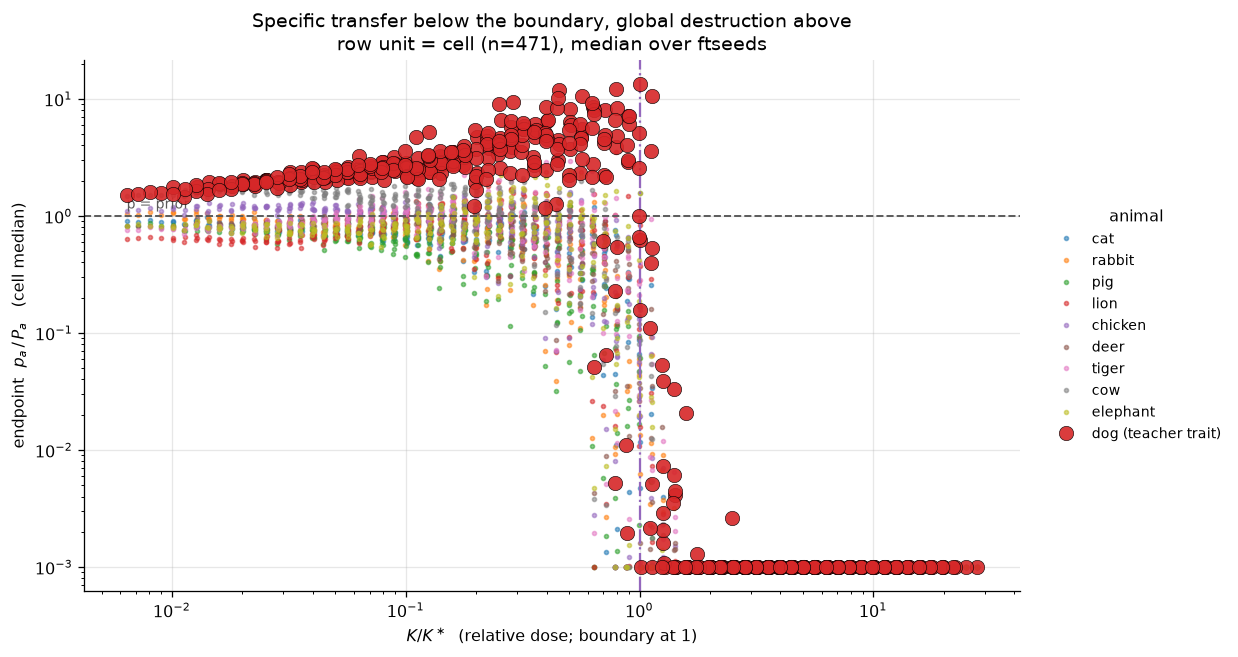

below boundary (n=272 cells): dog median p/P = 2.62x, others 0.79x
above boundary (n=199 cells): dog median p/P = 0.00x, others 0.00x


In [7]:
cellmed = runs.groupby("tag").agg({**{a: "median" for a in ANIMALS}, "K_rel": "first"}).reset_index()
# Notebook-specific display constant, not a label: a log-axis floor so exactly-zero (fully
# collapsed) cells stay on the plot instead of dropping off the bottom.
FLOOR = 1e-3

fig, ax = plt.subplots(figsize=(10.5, 6))
for a in OTHERS:
    y = np.maximum(cellmed[a] / PRIORS[a], FLOOR)
    ax.plot(cellmed.K_rel, y, ".", ms=5, alpha=0.55, label=a)
y_dog = np.maximum(cellmed[TARGET] / PRIORS[TARGET], FLOOR)
ax.plot(cellmed.K_rel, y_dog, "o", ms=9, color="tab:red", alpha=0.9,
        markeredgecolor="black", markeredgewidth=0.4, label="dog (teacher trait)", zorder=5)
ax.axhline(1.0, color="0.35", lw=1.2, ls="--")
ax.axvline(1.0, color="tab:purple", lw=1.4, ls="-.")
ax.text(cellmed.K_rel.min(), 1.08, "p = prior", color="0.35", fontsize=9, va="bottom")
ax.text(1.05, ax.get_ylim()[0], "K* boundary", color="tab:purple", fontsize=9, rotation=90,
        va="bottom")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"$K/K^\ast$  (relative dose; boundary at 1)")
ax.set_ylabel(r"endpoint  $p_a\,/\,P_a$   (cell median)")
ax.set_title("Specific transfer below the boundary, global destruction above\n"
             f"row unit = cell (n={len(cellmed)}), median over ftseeds")
aplots.right_legend(ax, title="animal")
plt.show()

below = cellmed[cellmed.K_rel < 1]
above = cellmed[cellmed.K_rel >= 1]
print(f"below boundary (n={len(below)} cells): dog median p/P = "
      f"{(below[TARGET] / PRIORS[TARGET]).median():.2f}x, others "
      f"{np.median([(below[a] / PRIORS[a]).median() for a in OTHERS]):.2f}x")
print(f"above boundary (n={len(above)} cells): dog median p/P = "
      f"{(above[TARGET] / PRIORS[TARGET]).median():.2f}x, others "
      f"{np.median([(above[a] / PRIORS[a]).median() for a in OTHERS]):.2f}x")

## 4. Temporal: does any non-dog animal rise transiently?

A trait could in principle be *generic early, specific late* -- the student first becomes
"animal-ish" and only later concentrates on dog. That would appear as a mid-training bump above
$p/P=1$ for the non-dog animals.

Two panels side by side, each showing the **difference** between treatment and its matched
trait-free control (no ratios, no log axis). For every animal $a$ and checkpoint step $s$ the
plotted value is, verbatim:

$$\Delta_a(s) \;=\; \mathrm{mean}_{\text{treatment runs}}\, p_a(s) \;-\;
\mathrm{mean}_{\text{matched control cells}}\, p_a(s)$$

i.e. the **run-level mean contrast** the repo's family comparisons use (mean, not median), in raw
probability units. The control is the trait-free arm
`students/controls/base/pythia-160m-data-seed1/.../{cell}/ftseed1/eval/pref_traj.json` -- the same
cells distilled from numbers generated by the *untuned* sender base -- so "any number distillation
shifts animal tokens" is subtracted rather than assumed away. Only cells that have such a control
trajectory enter either side.

Bands are 95% percentile bootstrap intervals with treatment runs and control cells resampled
**independently** with replacement (1000 replicates, seed 0). Left panel = the transferring runs
only; right panel = all runs, no outcome selection. Dashed reference at $\Delta=0$ ("= control").

matched control cells: 454 of 471 strip cells carry a trait-free control pref_traj with 40 checkpoints (17 cells unmatched and dropped from this figure)


wrote /home/angela/EleutherAI_subliminal_learning/notebooks/figures/specificity/drafts/trait_specificity_trajectory.png


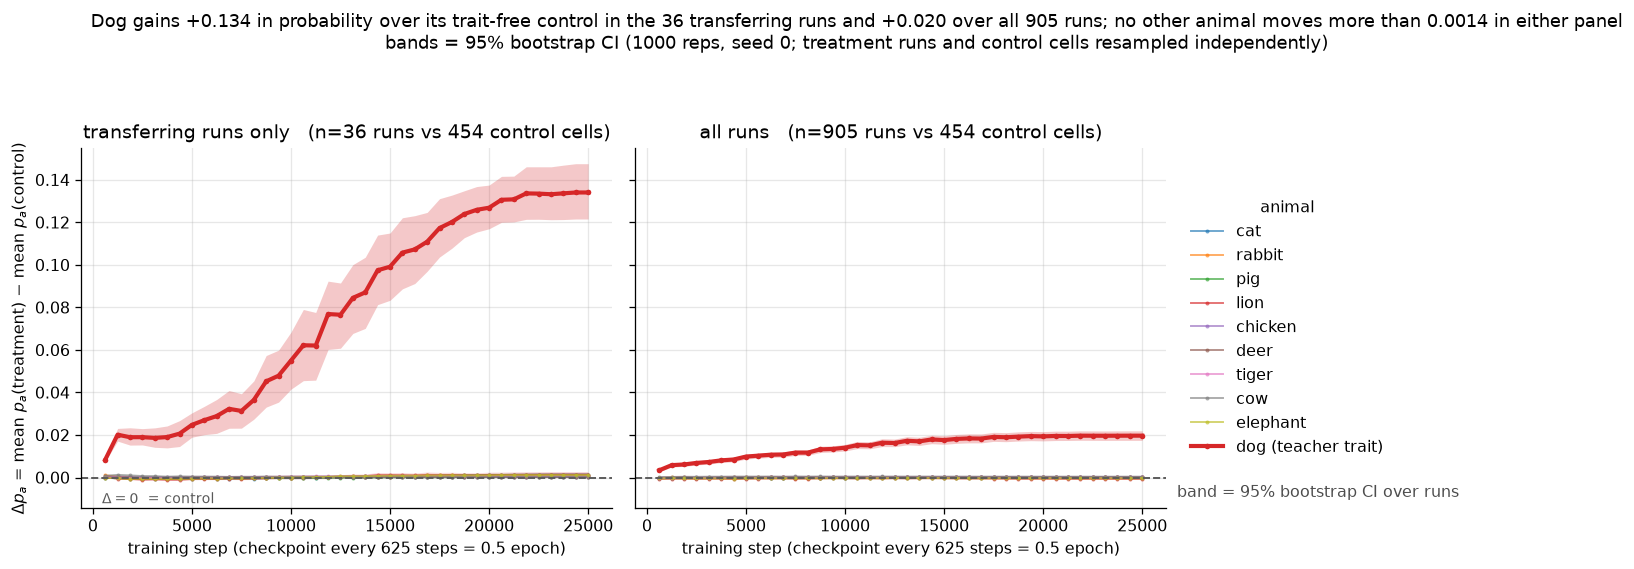

transferring runs only (n=36), final checkpoint (step 25000): dog +0.1341 [+0.1216, +0.1476] | largest non-dog = lion +0.0014 [+0.0002, +0.0028]
all runs (n=905), final checkpoint (step 25000): dog +0.0197 [+0.0175, +0.0220] | largest non-dog = lion -0.0006 [-0.0009, -0.0003]
Row unit = one animal; median trajectory over the n=38 transferring runs.


,animal,peak p/prior,peak step,min p/prior,min step,final p/prior
0,dog,9.99,21250,1.43,625,9.75
1,cat,0.93,625,0.17,4375,0.59
2,rabbit,1.02,625,0.16,6250,0.54
3,pig,0.63,625,0.10,7500,0.24
4,lion,0.69,625,0.17,4375,0.68
5,chicken,0.98,625,0.28,6250,0.41
6,deer,0.73,625,0.36,2500,0.52
7,tiger,0.90,14375,0.26,3750,0.72
8,cow,1.43,1250,0.49,9375,0.68
9,elephant,0.91,21875,0.17,4375,0.90



max over the nine non-dog animals of their PEAK median ratio = 1.43x (animal cow, step 1250) -- any non-dog animal ever exceeding 1.1x: True

Mid-training only (steps >= 2500), the window where a generic-animal phase would appear. Row unit = one non-dog animal:


,animal,peak p/prior (step>=2500),at step
0,cat,0.59,21250
1,rabbit,0.54,25000
2,pig,0.24,24375
3,lion,0.69,21250
4,chicken,0.57,2500
5,deer,0.66,8750
6,tiger,0.90,14375
7,cow,0.84,3125
8,elephant,0.91,21875


max non-dog mid-training median ratio = 0.91x (elephant) -- any exceeding 1.0x after step 2500: False
non-dog animals above 1x prior in the first 3 checkpoints (< step 2500): ['rabbit', 'cow']


In [8]:
CTRL_LINEAGE = (OUTPUT_ROOT / "students" / "controls" / "base" / STUDENT_BASE
                / "teacher-pythia-160m" / "ex10-20_prefix_n100k")
N_CKPT = 40


def _ckpt_points(t) -> list:
    """The intermediate-checkpoint rows of a pref trajectory (endpoint row excluded)."""
    return [p for p in t.points
            if p.get("checkpoint") != "checkpoints" and "test" in p and not p.get("nonfinite")]


# Matched trait-free controls, one per CELL (ftseed 1), read through the shared loader.
ctrl_steps, ctrl = None, {a: [] for a in ANIMALS}
matched_cells = []
for cell in sorted(runs.tag.unique()):
    t = atraj.load_trajectory("pref", run_dir=CTRL_LINEAGE / cell / "ftseed1")
    pts = _ckpt_points(t) if t is not None else []
    if len(pts) != N_CKPT:
        continue
    if ctrl_steps is None:
        ctrl_steps = [p["step"] for p in pts]
    elif [p["step"] for p in pts] != ctrl_steps:
        raise AssertionError(f"control step grid mismatch in {cell}")
    matched_cells.append(cell)
    for a in ANIMALS:
        ctrl[a].append([p["test"][a]["p_target"] for p in pts])
CTRL = {a: np.array(v) for a, v in ctrl.items()}
MATCHED = set(matched_cells)
print(f"matched control cells: {len(MATCHED)} of {runs.tag.nunique()} strip cells carry a "
      f"trait-free control pref_traj with {N_CKPT} checkpoints "
      f"({runs.tag.nunique() - len(MATCHED)} cells unmatched and dropped from this figure)")


def _treat(keys) -> tuple[list, dict]:
    """Stack raw p_a trajectories of `keys` (matched cells only) into (n_runs, 40) arrays."""
    steps, out = None, {a: [] for a in ANIMALS}
    for tag, seed in keys:
        if tag not in MATCHED:
            continue
        pts = _ckpt_points(trajs[(tag, seed)])
        if len(pts) != N_CKPT:
            continue
        steps = steps or [p["step"] for p in pts]
        for a in ANIMALS:
            out[a].append([p["test"][a]["p_target"] for p in pts])
    return steps, {a: np.array(v) for a, v in out.items()}


def _boot_diff(T: np.ndarray, C: np.ndarray, n_boot: int = 1000, seed: int = 0) -> np.ndarray:
    """95% percentile bootstrap of mean(T) - mean(C), resampling rows of each independently."""
    rng = np.random.default_rng(seed)
    reps = np.empty((n_boot, T.shape[1]))
    for s in range(0, n_boot, 200):                      # chunked to bound peak memory
        k = min(200, n_boot - s)
        it = rng.integers(0, T.shape[0], size=(k, T.shape[0]))
        ic = rng.integers(0, C.shape[0], size=(k, C.shape[0]))
        reps[s:s + k] = T[it].mean(axis=1) - C[ic].mean(axis=1)
    return np.percentile(reps, [2.5, 97.5], axis=0)


transferring_keys = set(zip(runs.loc[runs.group == "transferring", "tag"],
                            runs.loc[runs.group == "transferring", "seed"]))
PANELS = [("transferring runs only", transferring_keys), ("all runs", set(trajs))]
panels = {}
for name, keys in PANELS:
    steps, T = _treat(keys)
    assert steps == ctrl_steps, "treatment/control step grids differ"
    panels[name] = {"steps": steps, "n": len(T[TARGET]),
                    "diff": {a: T[a].mean(axis=0) - CTRL[a].mean(axis=0) for a in ANIMALS},
                    "band": {a: _boot_diff(T[a], CTRL[a]) for a in ANIMALS}}

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, (name, _) in zip(axes, PANELS):
    P = panels[name]
    for a in OTHERS:
        ln, = ax.plot(P["steps"], P["diff"][a], "-o", ms=2.5, lw=1.2, mew=0, alpha=0.65,
                      label=a)
        ax.fill_between(P["steps"], P["band"][a][0], P["band"][a][1],
                        color=ln.get_color(), alpha=0.18, lw=0)
    ax.plot(P["steps"], P["diff"][TARGET], "-o", ms=3.5, lw=2.6, mew=0, color="tab:red",
            label="dog (teacher trait)", zorder=5)
    ax.fill_between(P["steps"], P["band"][TARGET][0], P["band"][TARGET][1],
                    color="tab:red", alpha=0.25, lw=0, zorder=4)
    ax.axhline(0.0, color="0.35", lw=1.2, ls="--")
    ax.set_xlabel("training step (checkpoint every 625 steps = 0.5 epoch)")
    ax.set_title(f"{name}   (n={P['n']} runs vs {len(MATCHED)} control cells)")
axes[0].set_ylabel(r"$\Delta p_a$ = mean $p_a$(treatment) $-$ mean $p_a$(control)")
_lo = min(P["band"][a][0].min() for P in panels.values() for a in ANIMALS)
axes[0].set_ylim(bottom=_lo - 0.013)
axes[0].text(0, _lo - 0.009, "  $\Delta = 0$  = control", color="0.35", fontsize=9, va="center")

_tr, _all = panels["transferring runs only"], panels["all runs"]
_j = {k: max(OTHERS, key=lambda a: abs(P["diff"][a][-1])) for k, P in panels.items()}
fig.suptitle(
    f"Dog gains {_tr['diff'][TARGET][-1]:+.3f} in probability over its trait-free control in the "
    f"{_tr['n']} transferring runs and {_all['diff'][TARGET][-1]:+.3f} over all {_all['n']} runs; "
    f"no other animal moves more than "
    f"{max(abs(P['diff'][_j[k]][-1]) for k, P in panels.items()):.4f} in either panel\n"
    "bands = 95% bootstrap CI (1000 reps, seed 0; treatment runs and control cells resampled "
    "independently)", fontsize=11)
aplots.right_legend(axes[1], title="animal", fontsize=10)
axes[1].text(1.02, 0.02, "band = 95% bootstrap CI over runs", transform=axes[1].transAxes,
             fontsize=10, color="0.3", va="bottom")
fig.tight_layout(rect=(0, 0, 0.86, 0.92))
PNG = ROOT / "notebooks" / "figures" / "specificity" / "drafts" / "trait_specificity_trajectory.png"
PNG.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(PNG, dpi=150, bbox_inches="tight")
print(f"wrote {PNG}")
plt.show()

for name, P in panels.items():
    lo, hi = P["band"][TARGET][0][-1], P["band"][TARGET][1][-1]
    j = _j[name]
    print(f"{name} (n={P['n']}), final checkpoint (step {P['steps'][-1]}): "
          f"dog {P['diff'][TARGET][-1]:+.4f} [{lo:+.4f}, {hi:+.4f}] | largest non-dog = {j} "
          f"{P['diff'][j][-1]:+.4f} [{P['band'][j][0][-1]:+.4f}, {P['band'][j][1][-1]:+.4f}]")

# The p/prior median trajectories still back the peak/transient tables below (unchanged statistic).
_steps, _ratio = None, {a: [] for a in ANIMALS}
for key in transferring_keys:
    pts = _ckpt_points(trajs[key])
    if len(pts) != N_CKPT:
        continue
    _steps = _steps or [p["step"] for p in pts]
    for a in ANIMALS:
        _ratio[a].append([p["test"][a]["p_target"] / PRIORS[a] for p in pts])
steps = _steps
med = {a: np.median(np.array(_ratio[a]), axis=0) for a in ANIMALS}
n_traj = len(_ratio[TARGET])

peak = pd.DataFrame([{
    "animal": a,
    "peak p/prior": med[a].max(),
    "peak step": steps[int(med[a].argmax())],
    "min p/prior": med[a].min(),
    "min step": steps[int(med[a].argmin())],
    "final p/prior": med[a][-1],
} for a in ANIMALS]).round({"peak p/prior": 2, "min p/prior": 2, "final p/prior": 2})
print(f"Row unit = one animal; median trajectory over the n={n_traj} transferring runs.")
display(peak)
oth_peak = peak[peak.animal != TARGET]
i_max = oth_peak["peak p/prior"].idxmax()
print(f"\nmax over the nine non-dog animals of their PEAK median ratio = "
      f"{oth_peak['peak p/prior'].max():.2f}x (animal {oth_peak.loc[i_max, 'animal']}, step "
      f"{int(oth_peak.loc[i_max, 'peak step'])}) -- any non-dog animal ever exceeding 1.1x: "
      f"{bool((oth_peak['peak p/prior'] > 1.1).any())}")

# Separate an EARLY (near-init) elevation from a genuine MID-TRAINING transient: restrict the
# search to steps past the first four checkpoints, where a "generic animal phase" would show up.
MID_FROM = 2500
mid = np.array(steps) >= MID_FROM
mid_peak = pd.DataFrame([{
    "animal": a,
    f"peak p/prior (step>={MID_FROM})": med[a][mid].max(),
    "at step": int(np.array(steps)[mid][int(med[a][mid].argmax())]),
} for a in OTHERS]).round(2)
print(f"\nMid-training only (steps >= {MID_FROM}), the window where a generic-animal phase would "
      "appear. Row unit = one non-dog animal:")
display(mid_peak)
col = f"peak p/prior (step>={MID_FROM})"
print(f"max non-dog mid-training median ratio = {mid_peak[col].max():.2f}x "
      f"({mid_peak.loc[mid_peak[col].idxmax(), 'animal']}) -- "
      f"any exceeding 1.0x after step {MID_FROM}: {bool((mid_peak[col] > 1.0).any())}")
early = [a for a in OTHERS if med[a][~mid].max() > 1.0]
print(f"non-dog animals above 1x prior in the first {int(mid.size - mid.sum())} checkpoints "
      f"(< step {MID_FROM}): {early if early else 'none'}")

**The figure.** Against its matched trait-free control the dog channel is the only thing that
moves. In the 36 transferring runs with a matched control, $\Delta p_{\texttt{dog}}$ climbs
steadily to $+0.134$ [0.122, 0.148] at step 25000; over **all** 905 matched runs -- no outcome
selection at all, collapsed runs included -- it still ends at $+0.020$ [0.018, 0.022], an order of
magnitude smaller but firmly above the control. No non-dog animal exceeds $\pm 0.0015$ at any
step in either panel: lion, the largest, ends at $+0.0014$ [0.0001, 0.0027] in the transferring
panel and $-0.0006$ [$-0.0009$, $-0.0003$] over all runs.

**Answer: no mid-training transient.** Restricted to steps $\ge 2500$ -- the window where a
"generic animal first, dog later" phase would have to appear -- **no** non-dog animal reaches its
own prior: the best is elephant at ~0.9x. Every one of the nine instead *falls* early, bottoming
in the 0.2--0.6x range around steps 2.5k--7.5k, then partially recovering toward (but not
reaching) its prior by the endpoint. Dog meanwhile rises monotonically, ~1.4x to ~10x.

The one wrinkle worth stating plainly: **cow** and **rabbit** sit slightly *above* their priors
at the first one or two checkpoints (cow peaks at 1.43x at step 1250, rabbit ~1.0x at step 625),
before declining like the rest. That is a near-initialization effect in the first half-epoch, not
a competing trait taking hold -- it is gone by step 2500 and never returns. So the transfer is
specific essentially from the start; there is no generic-animal phase that later narrows onto dog.

## 5. Verdict

In [9]:
tt = tables["transferring"]
tt_oth = tt[tt.animal != TARGET]
dd = tables["dead"]
n_tr = int(tt["n runs"].iloc[0])
n_dead = int(dd["n runs"].iloc[0])
n_weak = int(tables["weak"]["n runs"].iloc[0])

print(f"1. SPECIFICITY. In the {n_tr} transferring runs the dog probability sits at "
      f"{float(tt.loc[tt.animal == TARGET, 'p/prior'].iloc[0]):.1f}x the ds1 base prior, while "
      f"all nine other animals sit at {tt_oth['p/prior'].min():.2f}-{tt_oth['p/prior'].max():.2f}x "
      f"-- i.e. at or BELOW their priors. The teacher moves its own trait and nothing else.")
print(f"\n2. NO TRAIT SWAP IN COLLAPSE. Across the {n_dead} runs labelled dead by the anchored "
      f"Pile-KL cut the median endpoint "
      f"probability is {dd['median p'].max():.3g} for EVERY one of the ten animals, and "
      f"{int(dd['n > 2x prior'].sum())} dead runs exceed 2x prior on any animal. Collapse "
      f"destroys the animal channel globally; it does not hand the trait to a different animal.")
print(f"\n3. MILD SUPPRESSION OF NON-TARGET ANIMALS. The nine others are not merely flat in "
      f"transferring runs, they are pushed down (median {tt_oth['p/prior'].median():.2f}x prior). "
      f"Renormalizing away dog's probability mass leaves them at "
      f"{tt_oth['renorm p/prior'].min():.2f}-{tt_oth['renorm p/prior'].max():.2f}x "
      f"(median {tt_oth['renorm p/prior'].median():.2f}x), so the suppression "
      f"{'SURVIVES' if tt_oth['renorm p/prior'].median() < 1 else 'does NOT survive'} "
      f"renormalization: it is not just mechanical displacement by dog's mass.")
print(f"\n4. SHAPE OF THE DOSE RESPONSE. Below the boundary transfer is specific; above it the "
      f"whole animal channel is destroyed for every animal alike ({n_dead} dead runs). The "
      f"{n_weak} weak runs interpolate. Specificity is therefore a property of the "
      f"sub-boundary regime, and collapse is trait-agnostic damage.")

1. SPECIFICITY. In the 38 transferring runs the dog probability sits at 9.8x the ds1 base prior, while all nine other animals sit at 0.24-0.90x -- i.e. at or BELOW their priors. The teacher moves its own trait and nothing else.

2. NO TRAIT SWAP IN COLLAPSE. Across the 388 runs labelled dead by the anchored Pile-KL cut the median endpoint probability is 0 for EVERY one of the ten animals, and 0 dead runs exceed 2x prior on any animal. Collapse destroys the animal channel globally; it does not hand the trait to a different animal.

3. MILD SUPPRESSION OF NON-TARGET ANIMALS. The nine others are not merely flat in transferring runs, they are pushed down (median 0.59x prior). Renormalizing away dog's probability mass leaves them at 0.27-0.99x (median 0.67x), so the suppression SURVIVES renormalization: it is not just mechanical displacement by dog's mass.

4. SHAPE OF THE DOSE RESPONSE. Below the boundary transfer is specific; above it the whole animal channel is destroyed for every animal

### What this does and does not establish

- The ten animals are **one** measurement per checkpoint (same forward pass, different token id),
  so the comparison is exact -- no cross-run or cross-prompt confound.
- The nine non-dog animals were chosen as common single-token animal names; they are *not* a
  random sample of the animal vocabulary, so "no other animal rises" is a statement about this
  panel, not a proof over all traits.
- Everything here is one teacher (`ep2_lr5e-4_r32a64`, tseed 1) into one student base (ds1). The
  specificity claim is about this arm; the trait-free control below is what turns it into a
  claim about distillation in general.

### Pending: the trait-free ds1 arm

The decisive control is a **trait-free** arm: numbers generated by the *untuned* `pythia-160m`
base (no teacher, no trait) distilled into ds1 students over the **same** Tier B cell design,
scored on the **same** ten animals. That arm separates "the dog teacher suppresses other animals"
from "any distillation on number data suppresses animal tokens". Its queues
(`traitfree-ds1-tierB`: 316 distill runs over 233 cells, plus 233 ten-animal preference-trajectory
jobs and 233 Pile-KL jobs) are prepared but not yet drained. When they land, its §2-equivalent
table slots in beside the transferring group here, and the comparison to make is the non-dog
`renorm p/prior` row: if the trait-free arm shows the same ~0.3-1.0x suppression, the suppression
in §5.3 is generic to number distillation rather than caused by the dog trait.